# 15 · Modelo dimensional y paquete Power BI\n\nConstrucción reproducible de un mart desde las salidas integradas de PE2. Cada hecho conserva su grano; no se unen hechos fila a fila. El notebook genera los CSV, metadatos de relaciones, una guía, medidas DAX iniciales y un ZIP listo para compartir/importar. Consulta `docs/modelo_data_warehouse_dashboard.md`.\n\nLa extracción representa un corte y no snapshots repetidos. El mart no habilita conclusiones temporales ni convierte publicaciones en transacciones. El generador prepara tablas y configuración, pero no crea un archivo PBIX.

In [1]:
from pathlib import Path
import subprocess, sys

# Resolver la raíz aunque nbconvert ejecute desde notebooks/.
ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src" / "build_dashboard_mart.py").exists()),
    Path.cwd()
)
script = ROOT / "src" / "build_dashboard_mart.py"
result = subprocess.run(
    [sys.executable, str(script)], cwd=ROOT, capture_output=True, text=True
)
print(result.stdout)
if result.returncode:
    print(result.stderr)
    raise RuntimeError("Falló el mart; revisar el error mostrado.")

{
  "paquete_powerbi": "/home/runner/work/TP_analitica_descriptiva_grupo1_2q2026/TP_analitica_descriptiva_grupo1_2q2026/data/processed/dashboard_mart_powerbi.zip",
  "relaciones": 15,
  "salidas": [
    {
      "tabla": "dim_fuente",
      "filas": 4
    },
    {
      "tabla": "dim_operacion",
      "filas": 4
    },
    {
      "tabla": "dim_tipo_propiedad",
      "filas": 13
    },
    {
      "tabla": "dim_moneda",
      "filas": 3
    },
    {
      "tabla": "dim_comuna",
      "filas": 15
    },
    {
      "tabla": "dim_barrio",
      "filas": 48
    },
    {
      "tabla": "dim_fecha",
      "filas": 5
    },
    {
      "tabla": "fact_publicacion",
      "filas": 67887
    },
    {
      "tabla": "fact_barrio_operacion",
      "filas": 192
    },
    {
      "tabla": "fact_kpi_barrio",
      "filas": 48
    },
    {
      "tabla": "fact_comuna_operacion",
      "filas": 60
    },
    {
      "tabla": "fact_kpi_comuna",
      "filas": 15
    },
    {
      "tabla": "fact_contex

## Entrega para el equipo de Power BI\n\nAl finalizar, compartir `data/processed/dashboard_mart_powerbi.zip`. Al descomprimirlo, importar los CSV ubicados dentro de `dashboard_mart/`; los archivos auxiliares están en `dashboard_mart/powerbi/`. Usar `relaciones.csv` para configurar relaciones 1:* con filtro Single y `esquema_powerbi.json` para revisar tipos. No importar las tablas de hechos como si fueran dimensiones ni relacionar hechos entre sí.\n\nEl paquete no contiene un PBIX terminado: deja el modelo tabular preparado para que el equipo agregue el diseño visual y valide las medidas en Power BI.

## Revisión para el equipo del dashboard

- Comprobar filas de `fact_publicacion` frente a la clave fuente × id × operación.
- Relacionar dimensiones con hechos (1:N, filtro unidireccional) y evitar relaciones hecho–hecho.
- Elegir la tabla según el nivel geográfico/modalidad; no mezclar comuna y barrio sin regla explícita.
- Usar medianas/percentiles para precios, filtros de moneda y operación; evitar sumar o promediar precios.
- Validar denominadores antes de reconstruir tasas y mostrar tamaño de muestra/cobertura en vistas territoriales.


## Panel visual de síntesis: disponibilidad del mart
Las tarjetas resumen filas construidas por tipo de tabla; el gráfico usa escala logarítmica porque la tabla de publicaciones tiene muchos más registros que los agregados territoriales. Comparar cantidades entre tablas requiere respetar sus granos.

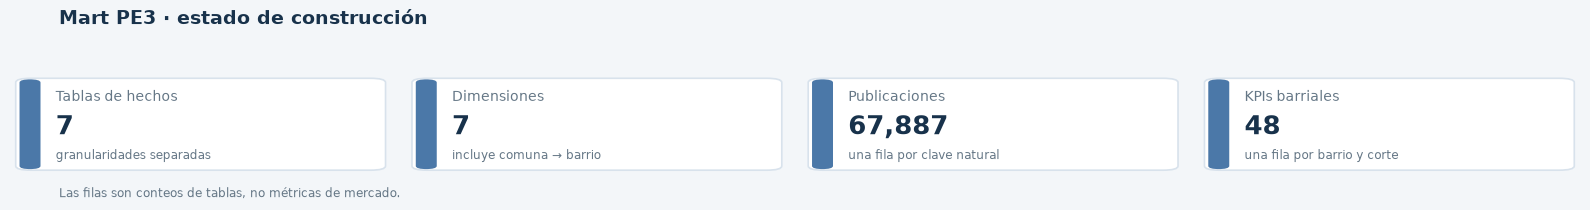

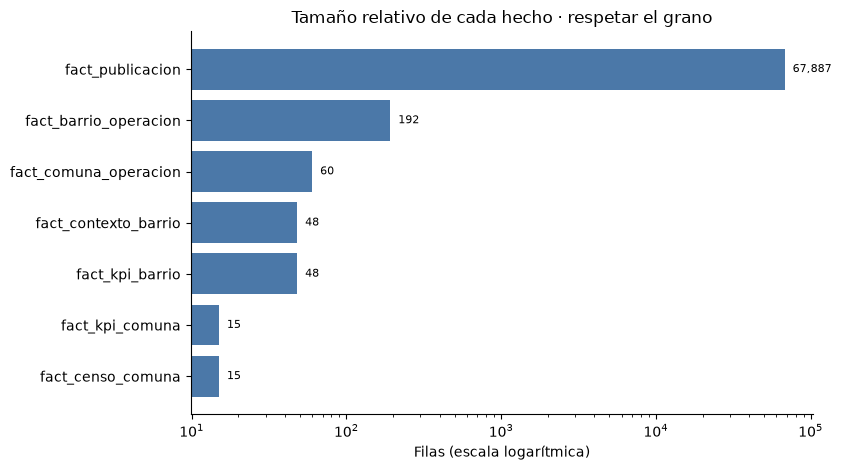

In [2]:
from src.pe3_visuals import kpi_cards
import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
mart_dir=ROOT/"data"/"processed"/"dashboard_mart"
manifest=json.loads((mart_dir/"data_model.json").read_text(encoding="utf-8"))
salidas=pd.DataFrame(manifest["salidas"])
n_facts=salidas["tabla"].str.startswith("fact_").sum()
n_dims=salidas["tabla"].str.startswith("dim_").sum()
def nrows(table):
    row=salidas.loc[salidas["tabla"]==table,"filas"]
    return int(row.iloc[0]) if len(row) else 0
kpi_cards([
 ("Tablas de hechos", str(n_facts), "granularidades separadas"),
 ("Dimensiones", str(n_dims), "incluye comuna → barrio"),
 ("Publicaciones", f"{nrows('fact_publicacion'):,}", "una fila por clave natural"),
 ("KPIs barriales", f"{nrows('fact_kpi_barrio'):,}", "una fila por barrio y corte"),
],title="Mart PE3 · estado de construcción",
note="Las filas son conteos de tablas, no métricas de mercado.")
frows=salidas[salidas["tabla"].str.startswith("fact_")].sort_values("filas")
fig,ax=plt.subplots(figsize=(8.5,4.8))
bars=ax.barh(frows["tabla"],frows["filas"],color="#4b78a8")
ax.set_xscale("log"); ax.set_xlabel("Filas (escala logarítmica)")
ax.set_title("Tamaño relativo de cada hecho · respetar el grano")
for bar,val in zip(bars,frows["filas"]):
    ax.text(val,bar.get_y()+bar.get_height()/2,f"  {val:,}",va="center",fontsize=8)
for spine in ("top","right"): ax.spines[spine].set_visible(False)
plt.tight_layout(); plt.show()

**Comprobación antes del dashboard.** Confirmar que el modelo de BI mantenga relaciones 1:N con filtro unidireccional, use una sola ruta geográfica y no una hechos entre sí. El precio es no aditivo, las tasas se conservan en su grano y la fecha de extracción no se debe presentar como serie temporal.